In [5]:
import json
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage.feature import hog
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report
from tqdm.auto import tqdm
import joblib

DATA_DIR = Path("data")
OUTPUT_DIR = DATA_DIR.parent / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
train_paths = sorted((DATA_DIR / "photos/train").glob("*.jpg"))
val_paths = sorted((DATA_DIR / "photos/val").glob("*.jpg"))
test_paths = sorted((DATA_DIR / "photos/test").glob("*.jpg"))
print(len(train_paths), len(val_paths), len(test_paths))

/Users/manoftheprincess/miniforge3/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


70000 10000 20000


In [6]:
def read_image(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def sign_boxes(path):
    label = DATA_DIR / "labels" / path.parent.name / f"{path.stem}.json"
    objects = json.loads(label.read_text())["frames"][0]["objects"]
    return np.asarray([
        [obj["box2d"][k] for k in ("x1", "y1", "x2", "y2")]
        for obj in objects
        if obj["category"] == "traffic sign" and "box2d" in obj
        and obj["box2d"]["x2"] > obj["box2d"]["x1"]
        and obj["box2d"]["y2"] > obj["box2d"]["y1"]
    ], dtype=float).reshape(-1, 4)


def iou(box, boxes):
    intersection = np.prod(np.maximum(0, np.minimum(box[2:], boxes[:, 2:]) -
                                      np.maximum(box[:2], boxes[:, :2])), axis=1)
    area = np.prod(box[2:] - box[:2])
    areas = np.prod(boxes[:, 2:] - boxes[:, :2], axis=1)
    return intersection / (area + areas - intersection + 1e-9)


def box_features(image, box):
    h, w = image.shape[:2]
    x1, y1 = np.floor(box[:2]).astype(int)
    x2, y2 = np.ceil(box[2:]).astype(int)
    x1, y1 = np.clip(x1, 0, w - 1), np.clip(y1, 0, h - 1)
    x2, y2 = np.clip(x2, x1 + 1, w), np.clip(y2, y1 + 1, h)
    crop = cv2.resize(image[y1:y2, x1:x2], (64, 64))
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    shape = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                cells_per_block=(2, 2), block_norm="L2-Hys")
    hsv = cv2.cvtColor(crop, cv2.COLOR_RGB2HSV)
    color = np.concatenate([
        np.histogram(hsv[:, :, k], bins=16, range=(0, upper))[0] / 4096
        for k, upper in enumerate((180, 256, 256))
    ])
    geometry = [np.log((x2-x1)/(y2-y1)), (x2-x1)/w, (y2-y1)/h]
    return np.concatenate([shape, color, geometry]).astype(np.float32)


def negative_boxes(image, truth, count=8):
    height, width = image.shape[:2]
    boxes = []
    for _ in range(count * 4):
        h = int(rng.integers(8, min(200, height) + 1))
        w = min(width, max(4, int(h * rng.choice([0.4, 0.7, 1, 1.5, 2.5, 4]))))
        x = int(rng.integers(width-w+1))
        y = int(rng.integers(height-h+1))
        box = np.array([x, y, x+w, y+h])
        if np.all(iou(box, truth) < 0.1):
            boxes.append(box)
        if len(boxes) == count:
            break
    return boxes

In [ ]:
def candidate_boxes(image):
    # First HSV color segmentation to find candidate boxes based on color
    height, width = image.shape[:2]
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    masks = [
        # color masks for red, yellow, green, blue, white
        cv2.inRange(hsv, (0, 70, 45), (12, 255, 255)) |
        cv2.inRange(hsv, (165, 70, 45), (179, 255, 255)),
        cv2.inRange(hsv, (15, 60, 45), (40, 255, 255)),
        cv2.inRange(hsv, (40, 55, 35), (140, 255, 255)),
        cv2.inRange(hsv, (0, 0, 150), (179, 65, 255))
    ]
    rectangles = []
    for mask in masks:
        # Fill small holes and remove small noise
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
        
        # Find contours and get bounding rectangles
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        # Add bounding rectangles to the list
        rectangles.extend(cv2.boundingRect(contour) for contour in contours)
        
        
    # Use MSER to detect regions of interest
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    mser = cv2.MSER_create()
    mser.setMinArea(30)
    mser.setMaxArea(int(height * width * 0.08))
    _, regions = mser.detectRegions(gray)
    rectangles.extend(regions)
    
    # Filter out boxes that are too small or too large
    boxes = set()
    for x, y, w, h in rectangles:
        if 4 <= w <= width * 0.6 and 6 <= h <= height * 0.6 and 0.2 <= w/h <= 6:
            for padding in (0, 0.12):
                dx, dy = round(w * padding), round(h * padding)
                boxes.add((max(0, x-dx), max(0, y-dy),
                           min(width, x+w+dx), min(height, y+h+dy)))
    return np.asarray(sorted(boxes), dtype=float).reshape(-1, 4)


def nms_indices(boxes, scores, threshold=0.4):
    order = np.argsort(scores)[::-1]
    if threshold >= 1:
        return order
    keep = []
    while len(order):
        index = order[0]
        keep.append(index)
        rest = order[1:]
        order = rest[iou(boxes[index], boxes[rest]) <= threshold]
    return np.asarray(keep, dtype=int)


def detect_signs(image, threshold=0.0, nms_threshold=0.4):
    boxes = candidate_boxes(image)
    if len(boxes) == 0:
        return boxes, np.empty(0)
    features = np.asarray([box_features(image, box) for box in boxes])
    scores = model.decision_function(features)
    selected = scores >= threshold
    boxes, scores = boxes[selected], scores[selected]
    keep = nms_indices(boxes, scores, nms_threshold)
    return boxes[keep], scores[keep]

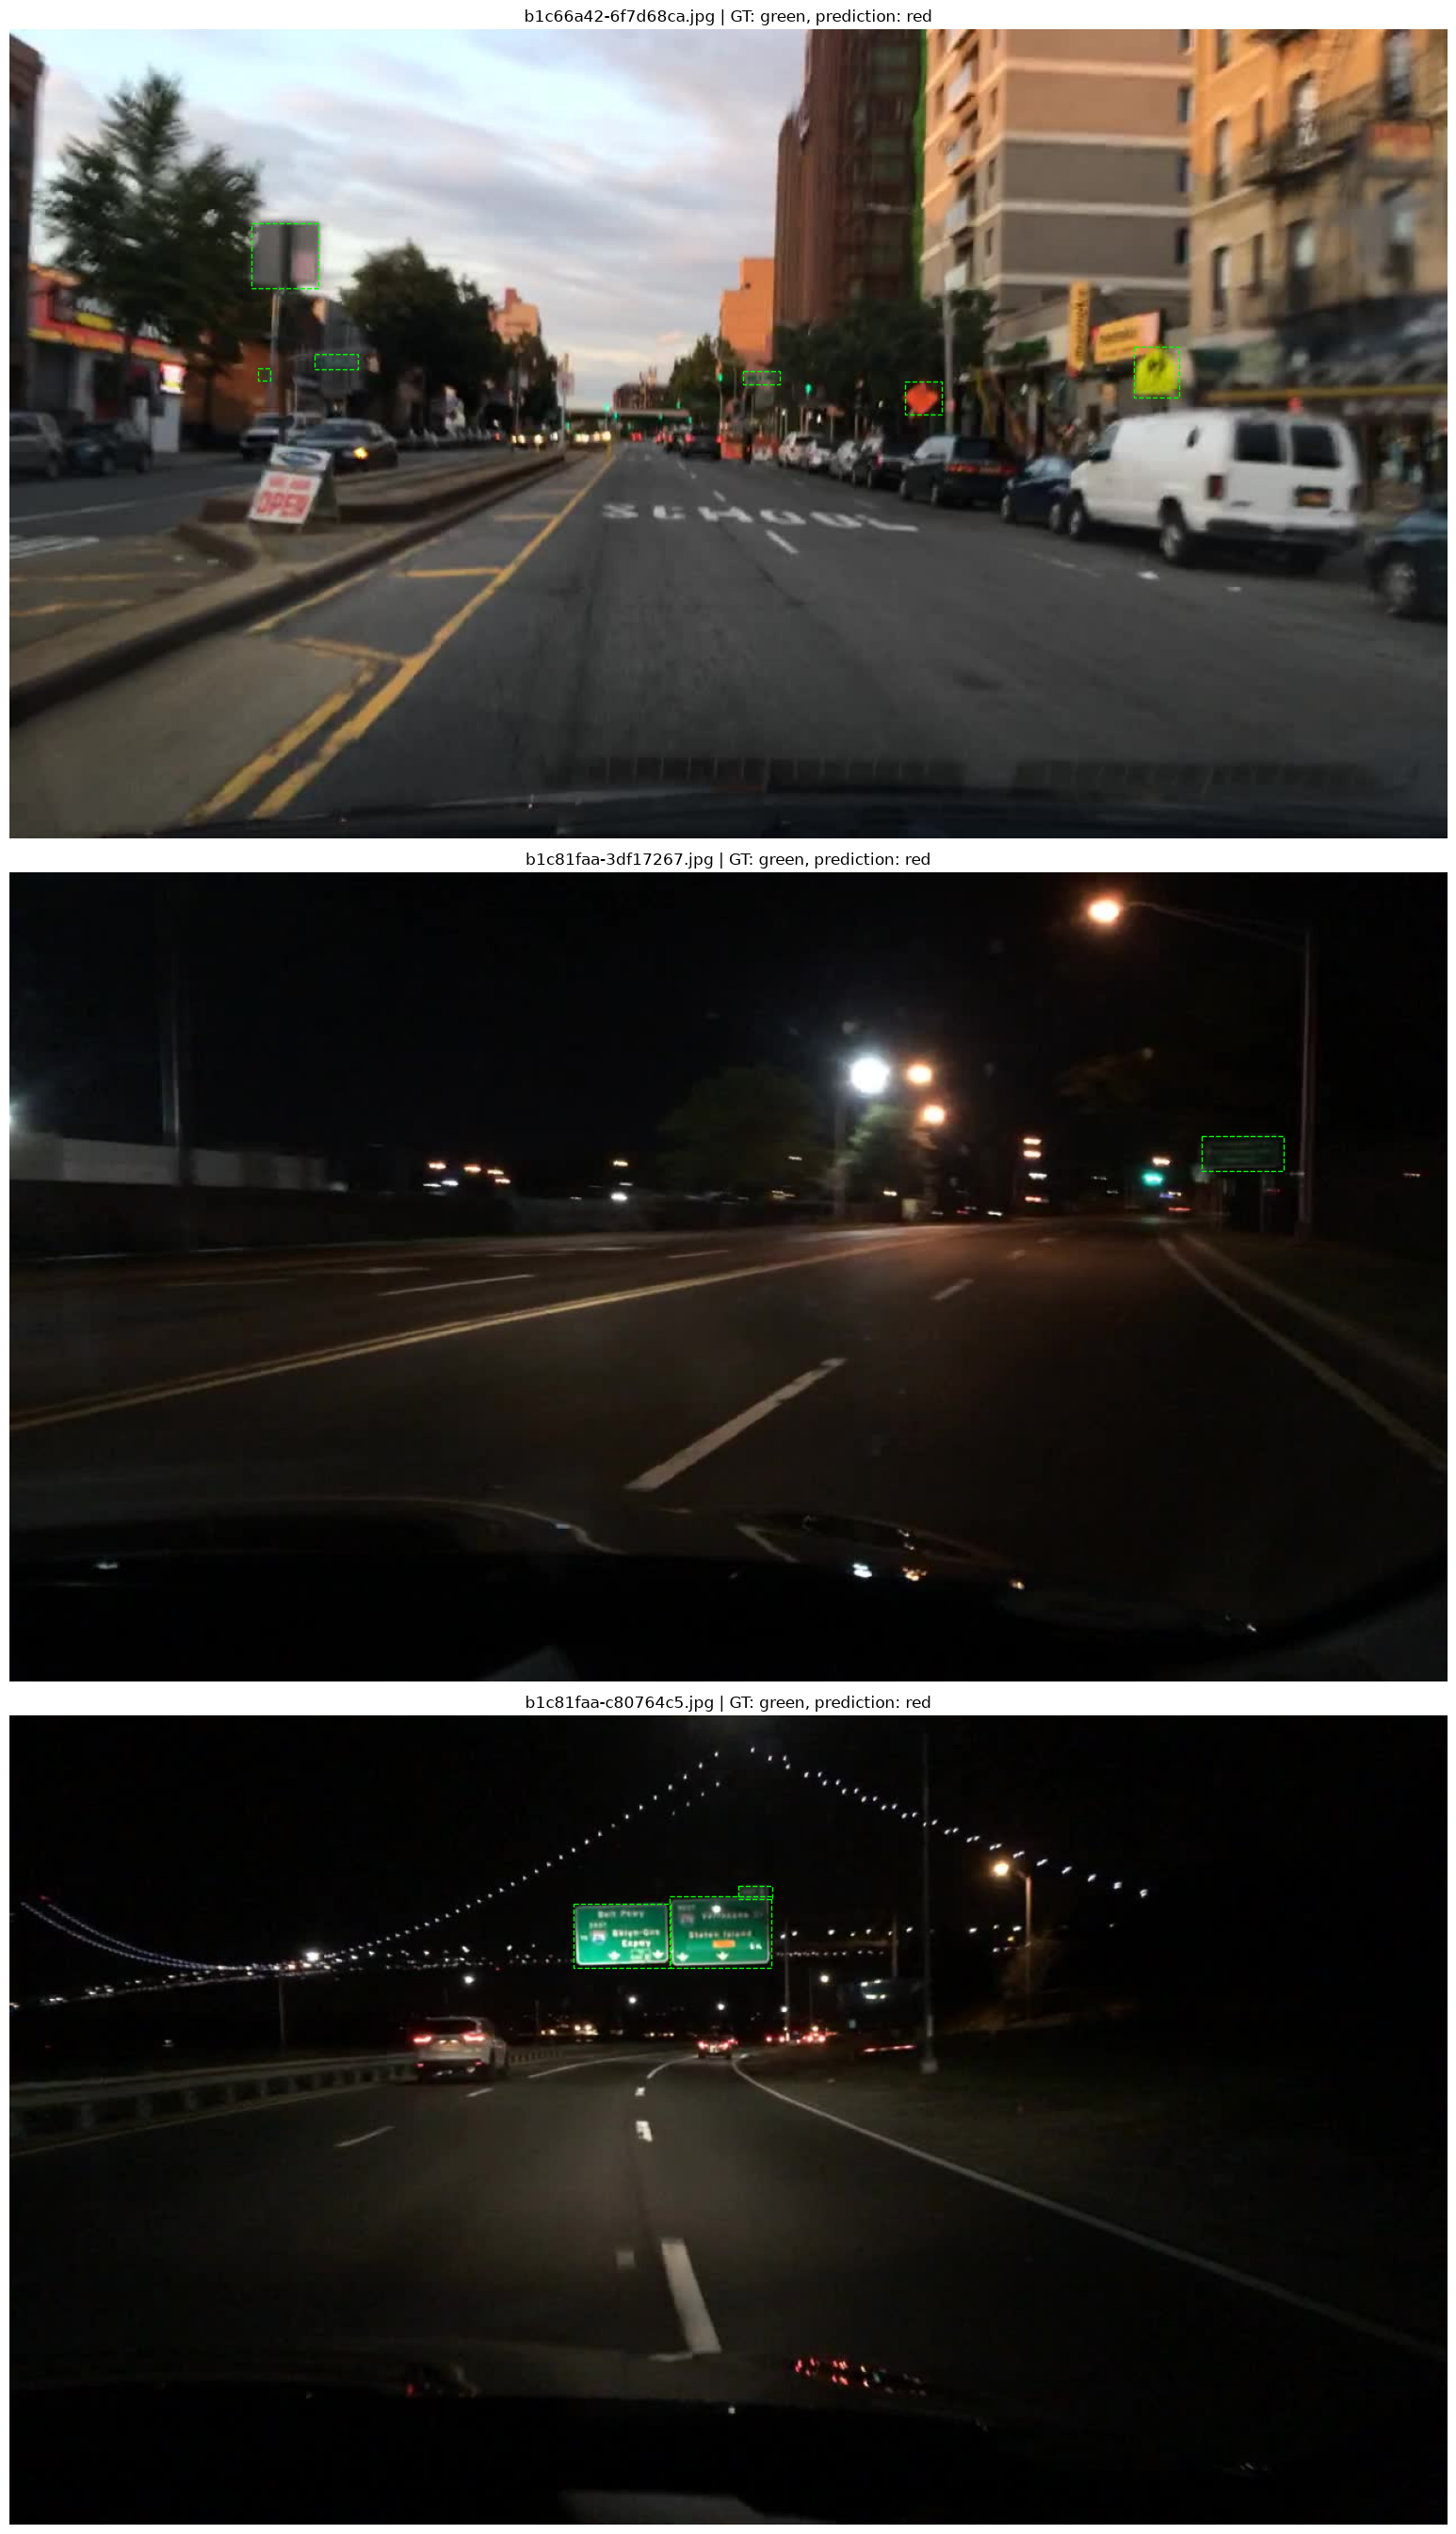

In [8]:
def show_detection(path, boxes, scores, ax):
    ax.imshow(read_image(path))
    for box in sign_boxes(path):
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                               fill=False, edgecolor="lime", linestyle="--"))
    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                               fill=False, edgecolor="red"))
        ax.text(x1, y1, f"{score:.2f}", color="red", fontsize=7)
    ax.set_title(f"{path.name} | GT: green, prediction: red")
    ax.axis("off")


fig, axes = plt.subplots(3, 1, figsize=(16, 27))
for ax, path in zip(axes, val_paths[:3]):
    show_detection(path, [], [], ax)
plt.tight_layout()
plt.show()

In [9]:
model = SGDClassifier(loss="hinge", alpha=0.0001, average=True, random_state=42)
for epoch in range(2):
    X, y = [], []
    for index in tqdm(rng.permutation(len(train_paths)), desc=f"Train {epoch+1}"):
        path = train_paths[index]
        image = read_image(path)
        truth = sign_boxes(path)
        for box in truth:
            X.append(box_features(image, box))
            y.append(1)
        for box in negative_boxes(image, truth):
            X.append(box_features(image, box))
            y.append(0)
        if len(y) >= 2048:
            model.partial_fit(np.asarray(X), y, classes=[0, 1])
            X, y = [], []
    if len(y):
        model.partial_fit(np.asarray(X), y, classes=[0, 1])
joblib.dump(model, OUTPUT_DIR / "traffic_sign_initial.joblib")

Train 2: 100%|██████████| 70000/70000 [09:56<00:00, 117.40it/s]


['outputs/traffic_sign_initial.joblib']

In [10]:
crop_X, crop_y = [], []
for path in tqdm(val_paths[:200], desc="Crop validation"):
    image = read_image(path)
    truth = sign_boxes(path)
    for box in truth:
        crop_X.append(box_features(image, box))
        crop_y.append(1)
    for box in negative_boxes(image, truth):
        crop_X.append(box_features(image, box))
        crop_y.append(0)
print(classification_report(crop_y, model.predict(np.asarray(crop_X)),
                            target_names=["background", "traffic_sign"], zero_division=0))
proposal_hits, proposal_total = 0, 0
for path in tqdm(val_paths[:20], desc="Candidate recall"):
    proposals = candidate_boxes(read_image(path))
    for box in sign_boxes(path):
        proposal_hits += int(np.any(iou(box, proposals) >= 0.5))
        proposal_total += 1
print("Candidate recall:", proposal_hits / max(proposal_total, 1))


Crop validation: 100%|██████████| 200/200 [00:01<00:00, 121.87it/s]


              precision    recall  f1-score   support

  background       0.97      0.98      0.97      1600
traffic_sign       0.95      0.92      0.93       657

    accuracy                           0.96      2257
   macro avg       0.96      0.95      0.95      2257
weighted avg       0.96      0.96      0.96      2257



Candidate recall: 100%|██████████| 20/20 [00:00<00:00, 25.70it/s]

Candidate recall: 0.43283582089552236


In [11]:
for round_number in range(2):
    mining_paths = rng.choice(train_paths, size=300, replace=False)
    for path in tqdm(mining_paths, desc=f"Hard negatives {round_number+1}"):
        image = read_image(path)
        truth = sign_boxes(path)
        boxes = candidate_boxes(image)
        if len(boxes) == 0:
            continue
        features = np.asarray([box_features(image, box) for box in boxes])
        scores = model.decision_function(features)
        hard = [i for i in np.argsort(scores)[::-1]
                if scores[i] > -1 and np.all(iou(boxes[i], truth) < 0.1)][:40]
        positives = [box_features(image, box) for box in truth]
        if len(hard) and len(positives):
            X = np.concatenate([features[hard], np.asarray(positives)])
            y = np.r_[np.zeros(len(hard)), np.ones(len(positives))]
            weights = np.r_[np.ones(len(hard)),
                            np.full(len(positives), len(hard)/len(positives))]
            model.partial_fit(X, y, classes=[0, 1], sample_weight=weights.astype(np.float32))
joblib.dump(model, OUTPUT_DIR / "traffic_sign.joblib")

Hard negatives 2: 100%|██████████| 300/300 [02:01<00:00,  2.46it/s]


['outputs/traffic_sign.joblib']

In [12]:
def match_boxes(boxes, truth):
    used = set()
    correct = []
    for box in boxes:
        overlaps = iou(box, truth)
        candidates = [i for i in range(len(truth)) if i not in used]
        best = max(candidates, key=lambda i: overlaps[i], default=-1)
        matched = best != -1 and overlaps[best] >= 0.5
        correct.append(matched)
        if matched:
            used.add(best)
    return np.asarray(correct, dtype=bool), [i for i in range(len(truth)) if i not in used]


def predict_dataset(paths, threshold=-2.0, nms_threshold=1.0):
    results = {}
    for path in tqdm(paths, desc="Detection"):
        boxes, scores = detect_signs(read_image(path), threshold, nms_threshold)
        results[path.name] = dict(boxes=boxes.tolist(), scores=scores.tolist())
    return results


def evaluate(predictions, paths, threshold, nms_threshold):
    tp, fp, fn = 0, 0, 0
    for path in paths:
        result = predictions[path.name]
        boxes = np.asarray(result["boxes"]).reshape(-1, 4)
        scores = np.asarray(result["scores"])
        selected = scores >= threshold
        boxes, scores = boxes[selected], scores[selected]
        boxes = boxes[nms_indices(boxes, scores, nms_threshold)]
        correct, missed = match_boxes(boxes, sign_boxes(path))
        tp += int(correct.sum())
        fp += int((~correct).sum())
        fn += len(missed)
    precision = tp / max(tp+fp, 1)
    recall = tp / max(tp+fn, 1)
    return dict(precision=precision, recall=recall,
                F1=2*precision*recall/max(precision+recall, 1e-9), TP=tp, FP=fp, FN=fn)

Detection: 100%|██████████| 3/3 [00:00<00:00,  3.53it/s]


,precision,recall,F1,TP,FP,FN
0,0.008403,0.3,0.016349,3,354,7


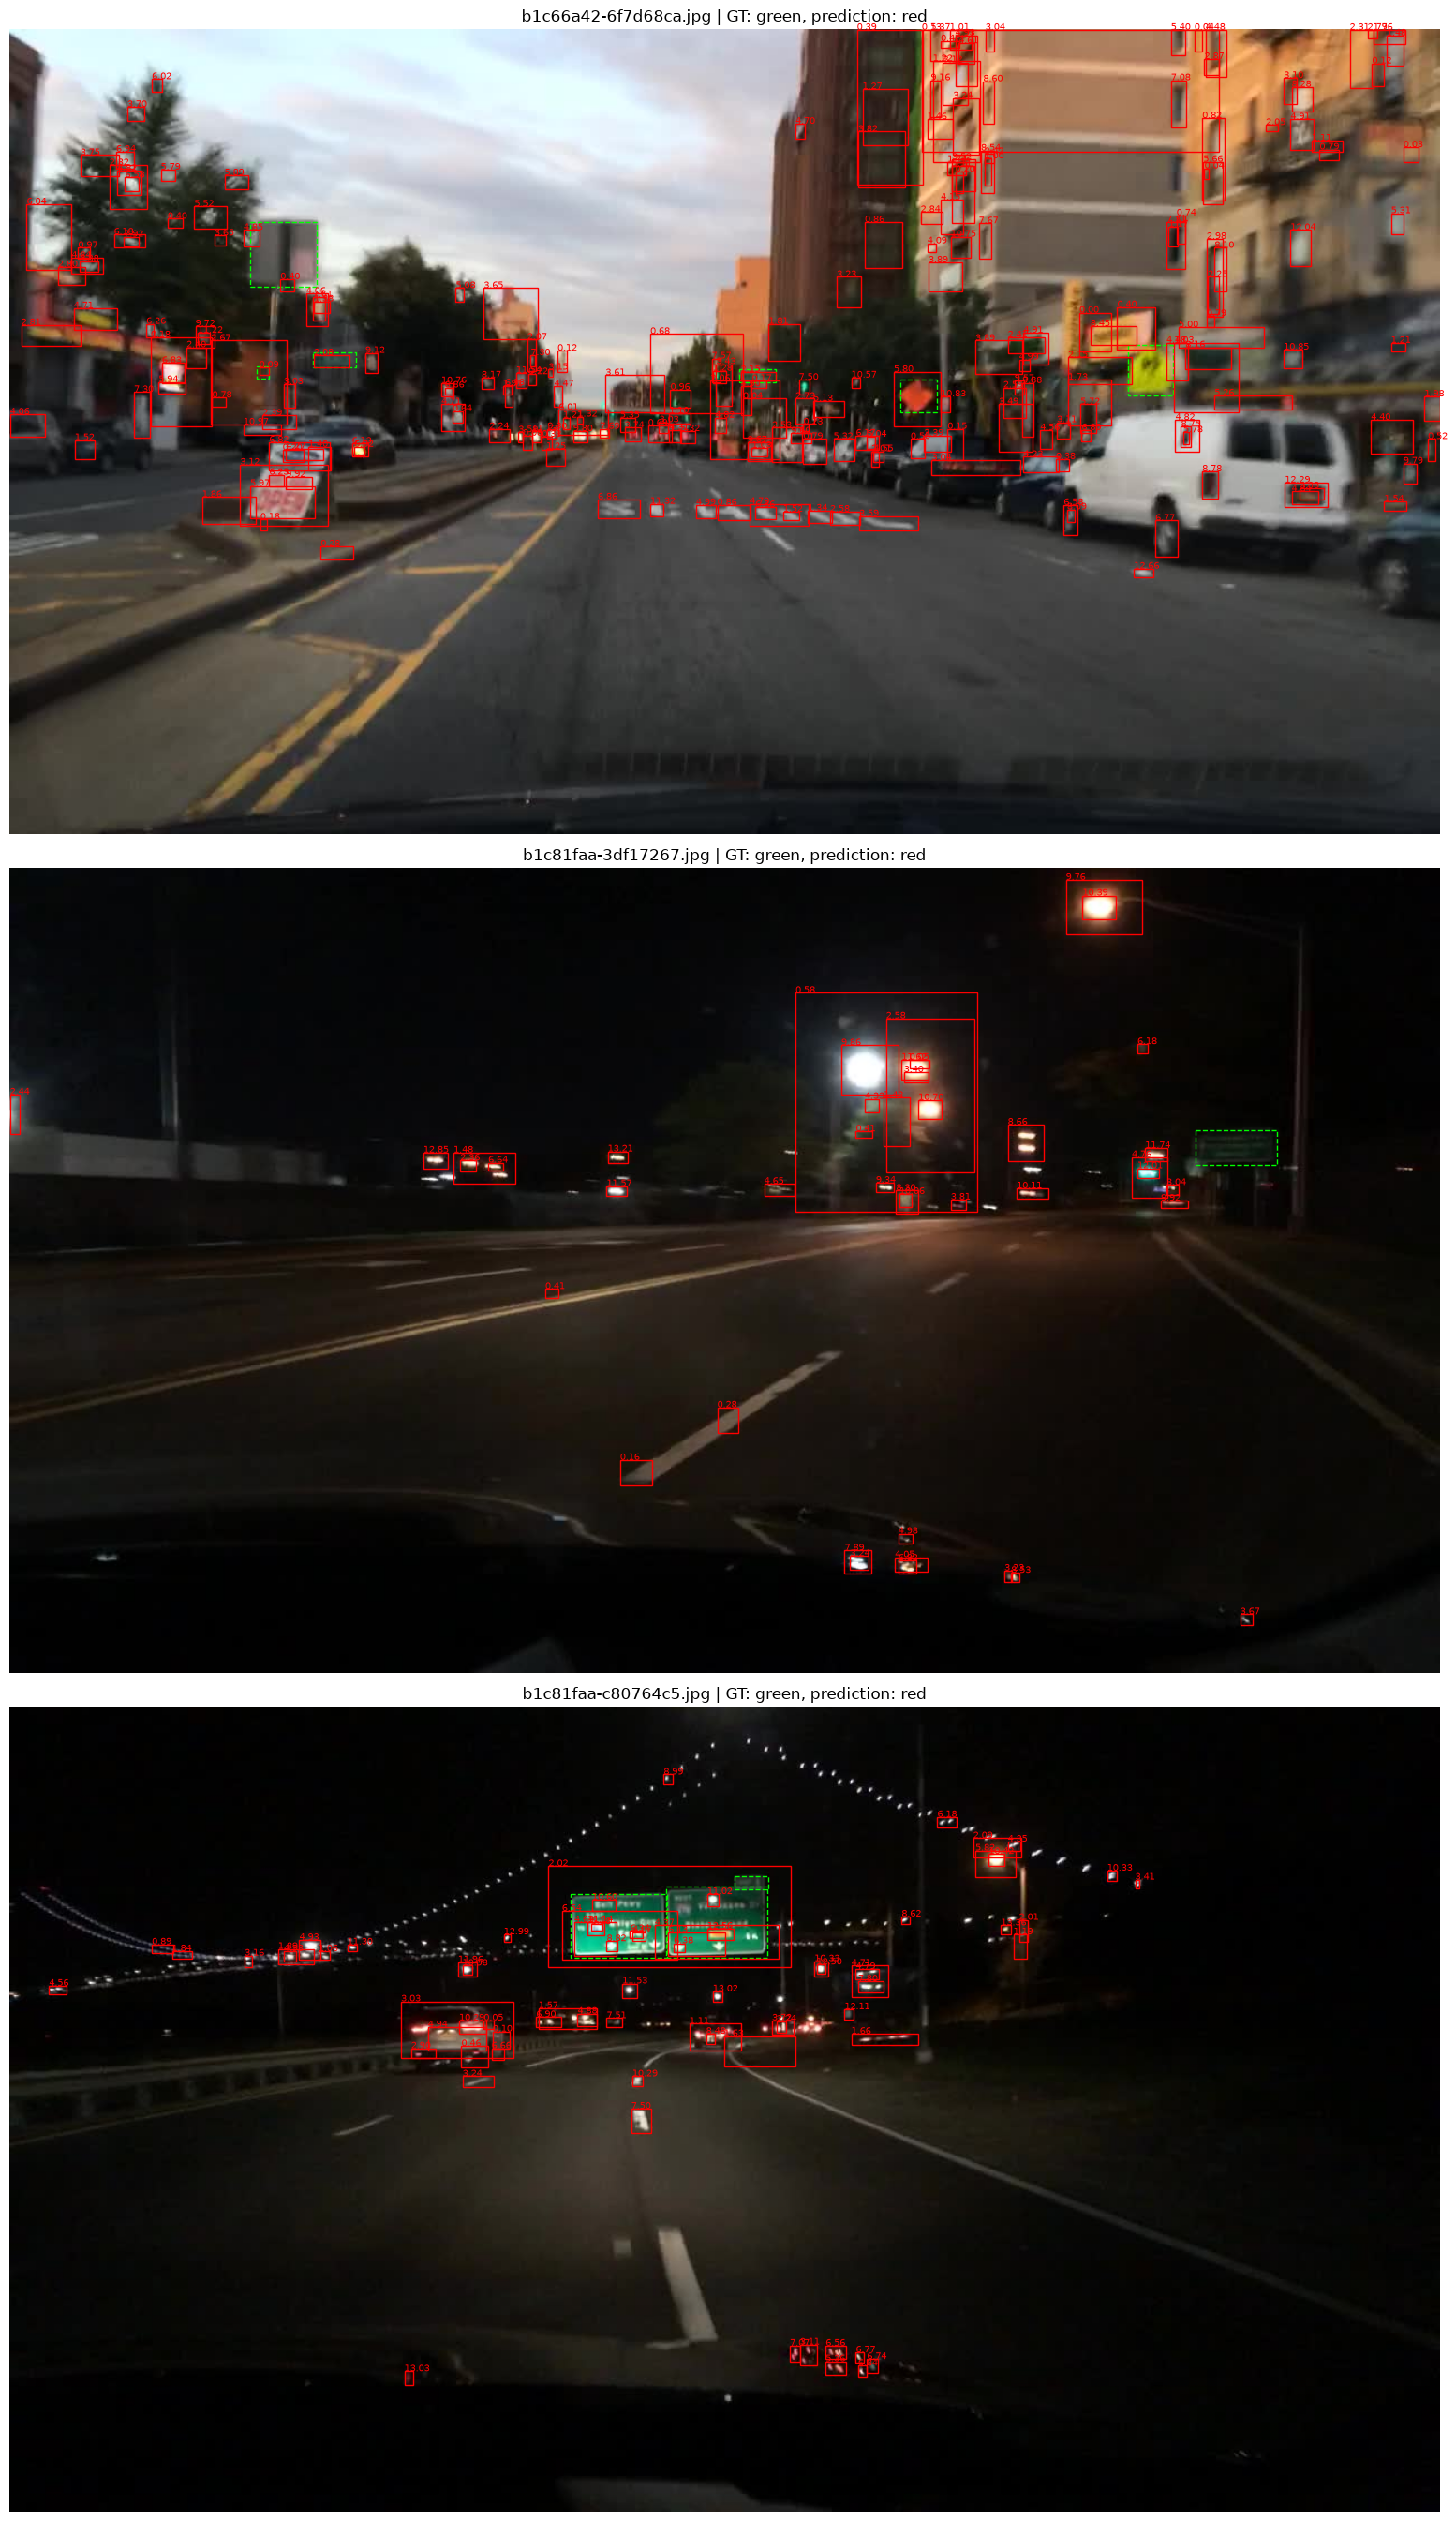

In [13]:
preview_paths = val_paths[:3]
preview_predictions = predict_dataset(preview_paths, 0.0, 0.4)
display(pd.DataFrame([evaluate(preview_predictions, preview_paths, 0.0, 0.4)]))
fig, axes = plt.subplots(3, 1, figsize=(16, 27))
for ax, path in zip(axes, preview_paths):
    result = preview_predictions[path.name]
    show_detection(path, result["boxes"], result["scores"], ax)
plt.tight_layout()
plt.show()

In [14]:
tuning_paths = val_paths
val_predictions = predict_dataset(tuning_paths)
rows = []
for threshold in [-2, -1, -0.5, 0, 0.5, 1, 2]:
    for nms_threshold in [0.3, 0.4, 0.5]:
        rows.append(dict(threshold=threshold, nms=nms_threshold,
                         **evaluate(val_predictions, tuning_paths, threshold, nms_threshold)))
val_results = pd.DataFrame(rows).sort_values("F1", ascending=False)
best = val_results.iloc[0]
score_threshold, nms_threshold = float(best["threshold"]), float(best["nms"])
val_results.to_csv(OUTPUT_DIR / "traffic_sign_validation.csv", index=False)
val_results

Detection: 100%|██████████| 10000/10000 [1:49:45<00:00,  1.52it/s]  


,threshold,nms,precision,recall,F1,TP,FP,FN
18,2.0,0.3,0.009810,0.334737,0.019062,11685,1179418,23223
19,2.0,0.4,0.009554,0.340781,0.018588,11896,1233190,23012
20,2.0,0.5,0.009179,0.343589,0.017879,11994,1294747,22914
15,1.0,0.3,0.008465,0.348430,0.016528,12163,1424772,22745
16,1.0,0.4,0.008216,0.354646,0.016059,12380,1494502,22528
17,1.0,0.5,0.007892,0.357998,0.015443,12497,1571060,22411
12,0.5,0.3,0.007875,0.353472,0.015408,12339,1554438,22569
13,0.5,0.4,0.007638,0.359860,0.014958,12562,1632185,22346
14,0.5,0.5,0.007335,0.363241,0.014379,12680,1716104,22228
9,0.0,0.3,0.007333,0.357139,0.014371,12467,1687608,22441


In [17]:
test_predictions = predict_dataset(test_paths, score_threshold, nms_threshold)
test_metrics = evaluate(test_predictions, test_paths, score_threshold, nms_threshold)
(OUTPUT_DIR / "traffic_sign_test_predictions.json").write_text(json.dumps(test_predictions))
pd.DataFrame([test_metrics]).to_csv(OUTPUT_DIR / "traffic_sign_test_metrics.csv", index=False)
display(pd.DataFrame([test_metrics]))

Detection: 100%|██████████| 20000/20000 [2:06:03<00:00,  2.64it/s]  


,precision,recall,F1,TP,FP,FN
0,0.009743,0.33227,0.018931,22924,2329957,46068


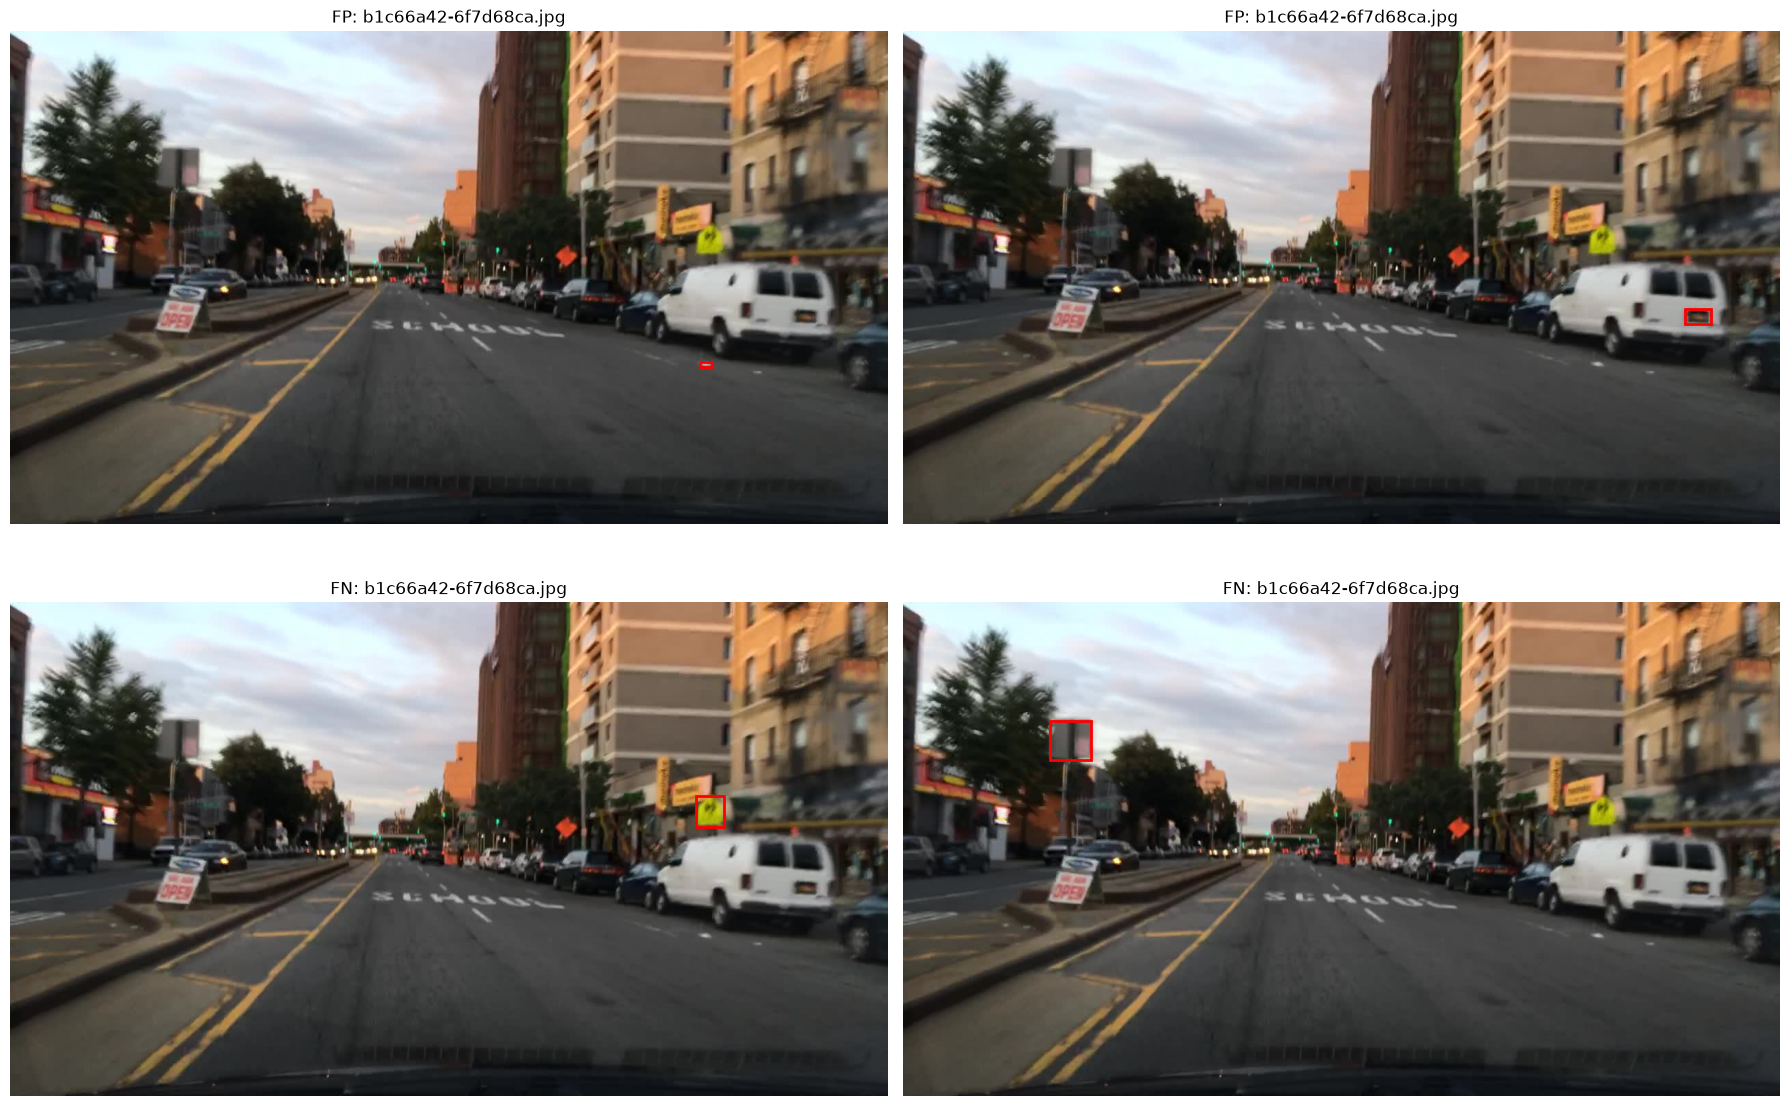

In [18]:
fp_examples, fn_examples = [], []
for path in preview_paths:
    result = preview_predictions[path.name]
    boxes = np.asarray(result["boxes"]).reshape(-1, 4)
    truth = sign_boxes(path)
    correct, missed = match_boxes(boxes, truth)
    fp_examples.extend((path, box) for box in boxes[~correct])
    fn_examples.extend((path, truth[i]) for i in missed)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for ax in axes.flat:
    ax.axis("off")
for ax, (kind, (path, box)) in zip(axes.flat,
    [("FP", item) for item in fp_examples[:2]] + [("FN", item) for item in fn_examples[:2]]):
    ax.imshow(read_image(path))
    x1, y1, x2, y2 = box
    ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor="red", linewidth=2))
    ax.set_title(f"{kind}: {path.name}")
plt.tight_layout()
plt.show()